# Signature methods for LQ stochastic control

*Aqsha, Bank & Sánchez-Betancourt, "Solving Linear-Quadratic Stochastic Control Problems with Signatures"* (arXiv:2602.23473)

**Running in two stages (compute, then plot).** The first code cell has three settings:
* `MODE = "compute"` runs every computation and saves the results of each expensive section to `CACHE_FILE`, a pickle file in the repository's `cache/` folder, after each section finishes.
* `MODE = "load"` skips those computations, reads the results from `CACHE_FILE`, and only prints the tables and draws the figures. Cheap steps, such as the test noise, the DPD benchmark and the sample-path figures, are recomputed in both modes.
* `USE_TEX` switches LaTeX rendering of the figures on or off.

So on a fast machine without LaTeX, run with `MODE = "compute"`, `USE_TEX = False`, then copy the cache file into `cache/` of the repository on the LaTeX machine and run with `MODE = "load"`, `USE_TEX = True`.

**Code.** All library functions (tensor algebra, shuffles, solvers, cost functionals, benchmarks, Monte Carlo and plotting tools) are in the package `lqsig` in `src/` of this repository; each section below names the module that implements it. Figures are written to `figures/signature_lq_control/` and cached results to `cache/`.

In [1]:
# ================= run settings =================
# Two-stage workflow:
#   1. on the fast machine (no LaTeX):  MODE = "compute", USE_TEX = False  -> runs everything, saves results to the cache
#   2. on the LaTeX machine:            MODE = "load",    USE_TEX = True   -> reads the cache, only prints and plots
# MODE = "compute" with USE_TEX = True also works (one machine, everything at once).
MODE = "load"                         # "compute" or "load"
USE_TEX = True                          # False on machines without a LaTeX installation
# =================================================

import os, sys, time, gc
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"

def _find_repo(start):
    """The repository root: the first folder above `start` that contains src/lqsig."""
    p = os.path.abspath(start)
    while not os.path.isdir(os.path.join(p, "src", "lqsig")):
        if os.path.dirname(p) == p:
            raise FileNotFoundError("cannot find the repository root (the folder that contains src/lqsig)")
        p = os.path.dirname(p)
    return p

REPO = _find_repo(os.getcwd())
if os.path.join(REPO, "src") not in sys.path:          # not needed after `pip install -e .`
    sys.path.insert(0, os.path.join(REPO, "src"))
from lqsig import *                                    # the shared library (src/lqsig)

np.set_printoptions(precision=5, suppress=True, linewidth=120)
setup_matplotlib(USE_TEX)
FIG_DIR = set_figure_dir(os.path.join(REPO, "figures", "signature_lq_control"))
CACHE_FILE = os.path.join(REPO, "cache", "signature_lq_control.pkl")
_results = ResultCache(MODE, CACHE_FILE)
cache_save, cache_load = _results.save, _results.load

# One seed for every random draw in the notebook: each experiment uses default_rng(SEED + its own offset).
SEED = 0
np.random.seed(SEED)

load mode: 3 cached sections read from C:\Users\User\Documents\GitHub\optimal-control-with-signatures\cache\signature_lq_control.pkl: ['brownian_2d', 'fbm_additive', 'fbm_additive_grid']


### Expected signature of time-augmented Brownian motion (Fawcett)

$$\mathbb E[\widehat{\mathbb W}_T]=\exp_\otimes\!\Big(T\big(\mathbf 1+\tfrac12\textstyle\sum_{d=1}^D \mathbf{(d{+}1)}\otimes\mathbf{(d{+}1)}\big)\Big),$$

In [2]:
# sanity checks
rng = np.random.default_rng(SEED + 0)
d, L = 3, 3
ts = TensorSpace(d, L)
g = [rng.normal(size=d**n) for n in range(2 * L + 1)]
x, y = rng.normal(size=ts.dim), rng.normal(size=ts.dim)
lhs = sum(a @ b for a, b in zip(shuffle_product(to_levels(x, ts), to_levels(y, ts), 2 * L, d), g))
print("<x ш y, g> explicit vs pairing matrix:", lhs, x @ pairing_matrix(g, L, L, d) @ y)
ES = expected_signature_bm(2, 1.0, 8)
G0 = running_functional(ES, 0, 3, 3)
print("E∫ t dt =", G0[1][0], "(1/2);   E∫ (W_t^1)^2/2 dt =", G0[2][4], "(1/4);   E∫ t·t dt =", running_functional(ES, 1, 2, 3)[1][0], "(1/3)")

<x ш y, g> explicit vs pairing matrix: 57.25186085107153 57.25186085107147
E∫ t dt = 0.5 (1/2);   E∫ (W_t^1)^2/2 dt = 0.25 (1/4);   E∫ t·t dt = 0.3333333333333333 (1/3)


### Consistency checks on a multi-dimensional example ($N=D=K=2$)
The checks cover: (i) the three solvers, including the proposed recursion (A); and (ii) exact quadratic assembly against the paper's black box with polarisation.

In [3]:
# mm = LQModel(T=1.0, X0=[1.0, -0.5], b0=[0.2, 0.0],
#              b1=[[1.0, 0.0], [0.3, 0.8]],                       # N x K
#              b2=[[-0.3, 0.4], [0.2, -0.1]],                     # N x N
#              sigma0=[[0.3, 0.1], [0.0, 0.25]],                  # N x D
#              sigma2=[[[0.2, 0.0], [0.0, 0.1]],                  # N x D x N
#                      [[0.1, 0.15], [-0.1, 0.2]]],
#              A=[np.eye(2)], B=[0.5 * np.eye(2), 0.5 * np.eye(2)],   # B(t) = 0.5 (1 + t) I
#              C=[[0.1, 0.0]], Dlin=[[0.0, 0.05]],
#              E=[[1.0, 0.2], [0.2, 0.5]], G=[0.1, -0.1])

mm = LQModel(T=1.0, X0=[10.0, -5.0], b0=[2.0, 0.0],
             b1=[[1.0, 0.0], [0.2, 0.8]],                       # N x K
             b2=[[-0.3, 0.7], [0.5, -0.5]],                     # N x N
             sigma0=[[0.9, 0.1], [0.0, 1.0]],                  # N x D
             sigma2=[[[0.60, 0.0], [0.0, 0.4]],                  # N x D x N
                     [[0.1, 0.30], [-0.4, 0.2]]],
             A=[0*np.eye(2)], B=[0.5 * np.eye(2), 0.5 * np.eye(2)],   # B(t) = 0.5 (1 + t) I
             C=[[0.0, 0.0]], Dlin=[[0.0, 0.0]],
             E=np.eye(2), G=[0.0, 0.0])

# (i) solvers
L, M = 4, 2
ts = TensorSpace(mm.d, L); q = build_q(mm); p0, pU = build_p(mm, L, M)
p = np.concatenate([p0[None], pU])                     # batch of 1 + P right-hand sides
out = {}
for name, f in SOLVERS.items():
    t0 = time.perf_counter(); out[name] = f(p, q, ts); out[name + '_t'] = time.perf_counter() - t0
print("max|picard - levelwise| =", np.abs(out['picard'] - out['levelwise']).max(),
      "  max|resolvent - levelwise| =", np.abs(out['resolvent'] - out['levelwise']).max())
print("times [ms]:", {k: round(1e3 * out[k + '_t'], 2) for k in SOLVERS})
print("a few coefficients of X^(1) for u = 0:")
for w in [(), (0,), (1,), (2,), (1, 1), (0, 1), (1, 0)]:
    print(f"   word {TensorSpace.word_str(w):>3}: {out['levelwise'][0, 0, ts.index(w)]: .5f}")

# (ii) exact assembly vs paper black box + polarisation
L, M = 3, 1
r = solve_signature_lq(mm, L, M)
ES_bb = expected_signature_bm(mm.D, mm.T, 2 * L + mm.m_max + 1)
f = lambda th: blackbox_cost(mm, th, L, M, ES_bb, solver='picard')
c0, h, H = polarisation_coefficients(f, len(r['theta']))
print("\nblack box vs exact assembly: |Δc0|, max|Δh|, max|ΔH| =", abs(c0 - r['c0']), np.abs(h - r['h']).max(), np.abs(H - r['H']).max())


max|picard - levelwise| = 0.0   max|resolvent - levelwise| = 8.881784197001252e-16
times [ms]: {'picard': 2.11, 'levelwise': 0.29, 'resolvent': 0.97}
a few coefficients of X^(1) for u = 0:
   word   ∅:  10.00000
   word   1: -4.50000
   word   2:  6.90000
   word   3: -1.90000
   word  22:  4.14000
   word  12: -2.70000
   word  21: -2.42000

black box vs exact assembly: |Δc0|, max|Δh|, max|ΔH| = 5.684341886080802e-14 1.176836406102666e-14 4.438116540939063e-14


## Multi-dimensional example: $N=2$ states, $D=2$ Brownian motions, $K=2$ controls

In [4]:
Ls2, Ms2 = [1, 2, 3, 4, 5, 6, 7], [0, 1, 2, 3]
n_mc2, steps_mc2 = 20000, 500; dt_mc2 = mm.T / steps_mc2
if MODE == "compute":
    ES2 = expected_signature_bm(mm.D, mm.T, 2 * max(Ls2) + mm.m_max + 1)
    trunc2 = np.full((len(Ls2), len(Ms2)), np.nan)
    sols2, timing = {}, {}
    for i, L in enumerate(Ls2):
        t0 = time.perf_counter(); F = CostFunctionals(mm.D, mm.T, L, max(Ms2), mm.m_max, ES=ES2); tF = time.perf_counter() - t0
        for j, M in enumerate(Ms2):
            t0 = time.perf_counter(); r = solve_signature_lq(mm, L, M, F=F); ts_ = time.perf_counter() - t0
            sols2[(L, M)] = r; timing[(L, M)] = (tF, ts_)
            trunc2[i, j] = r['value']
    del ES2, F; gc.collect()

    # Monte Carlo on common noise: every u^{L,M} and the optimal feedback u* (Itô Euler, 10,000 paths, 500 steps)
    dW_mc2 = np.random.default_rng(SEED + 1).normal(scale=np.sqrt(dt_mc2), size=(n_mc2, steps_mc2, mm.D))
    t0 = time.perf_counter()
    cost2, c_ref2, d2_2, q2_2 = simulate_many(mm, dW_mc2, dt_mc2, [(sols2[k]['theta'], k[1]) for k in sols2],
                                        riccati_feedback(mm, steps_mc2))
    t_mc2 = time.perf_counter() - t0
    del dW_mc2; gc.collect()
    cache_save("brownian_2d", sols2=sols2, trunc2=trunc2, timing=timing,
               cost2=cost2, c_ref2=c_ref2, d2_2=d2_2, q2_2=q2_2, t_mc2=t_mc2)
else:
    globals().update(cache_load("brownian_2d"))
mc2 = mc_grid(list(sols2), cost2, c_ref2, d2_2, q2_2)
print(f"Monte Carlo: {n_mc2} paths, {steps_mc2} steps, {len(mc2) + 1} controls on common noise ({t_mc2:.1f}s)")
print(f"MC cost of u*: {fmt_mc(c_ref2, 5)}   [mean ± 95% CI]")
print_grid(mc2, Ls2, Ms2, 5)
print("\ntruncated objective J^L(θ^{L,M})")
for L, row in zip(Ls2, trunc2): print(f"L={L}: " + "  ".join(f"{v:9.5f}" for v in row))
Lt, Mt = max(Ls2), max(Ms2)
print(f"time to build cost functionals for L={Lt}: {timing[(Lt, Mt)][0]:.2f}s; solve for (L,M)=({Lt},{Mt}): {timing[(Lt, Mt)][1]:.3f}s")

Monte Carlo: 20000 paths, 500 steps, 29 controls on common noise (79.7s)
MC cost of u*: 55.20611 ± 1.03141   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:     40.80002 ± 3.07676      63.06286 ± 3.44491      81.18557 ± 3.93590      89.90004 ± 4.21233
L=2:     26.61716 ± 2.33191      11.93250 ± 1.38150      48.69763 ± 2.85292      71.47154 ± 3.72638
L=3:     26.48013 ± 2.29348       4.19636 ± 0.85088       4.27687 ± 0.62792      58.76800 ± 3.14126
L=4:     26.33434 ± 2.23614       4.03730 ± 0.86226       1.48493 ± 0.33320       2.98567 ± 0.38096
L=5:     26.33374 ± 2.23570       3.97885 ± 0.82714       0.51112 ± 0.27617       0.94424 ± 0.12708
L=6:     26.33147 ± 2.23299       3.97982 ± 0.83008       0.49549 ± 0.26332       0.11263 ± 0.08186
L=7:     26.33149 ± 2.23300       3.97892 ± 0.82867       0.49442 ± 0.26309       0.07594 ± 0.07134

relative excess cost (J(u^{L,M}) − J(u*)) / J(u*)  [%, ± 95% CI]     rows: L, 

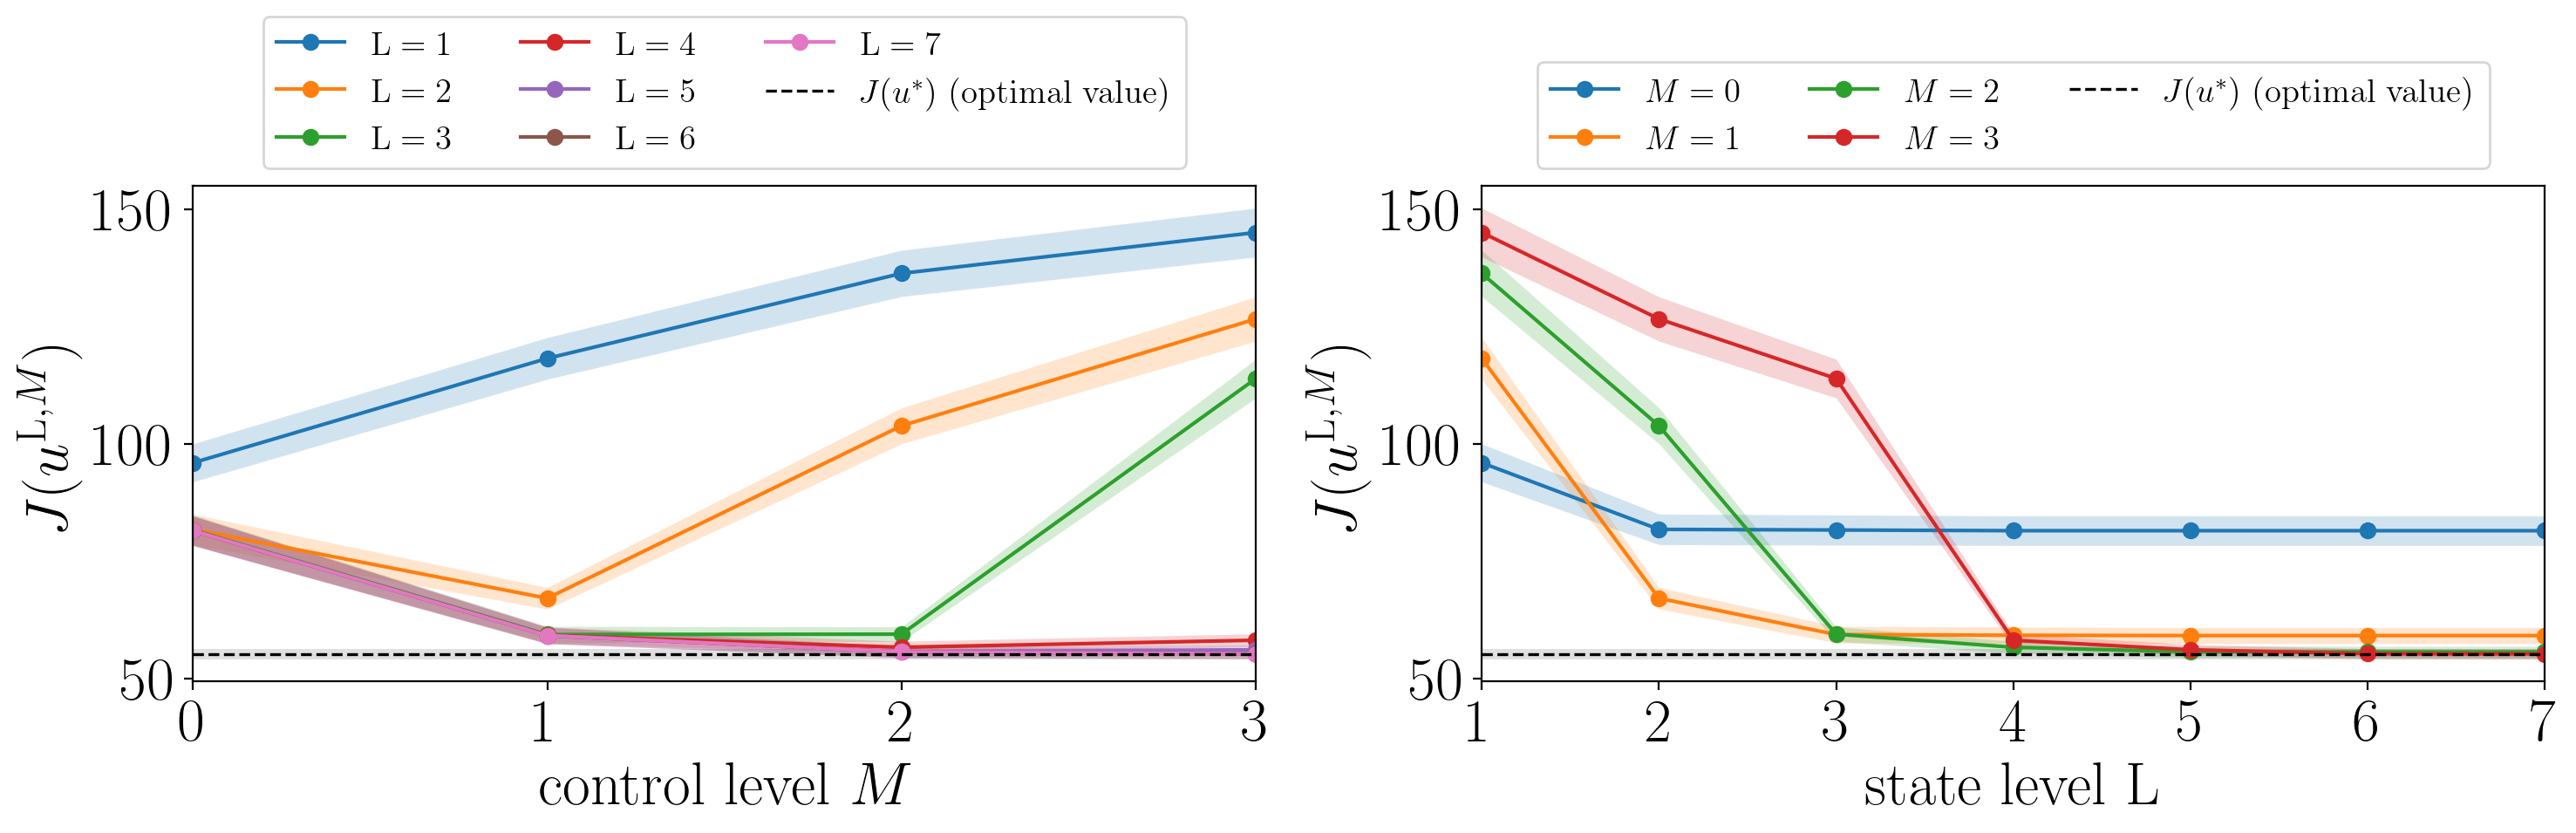

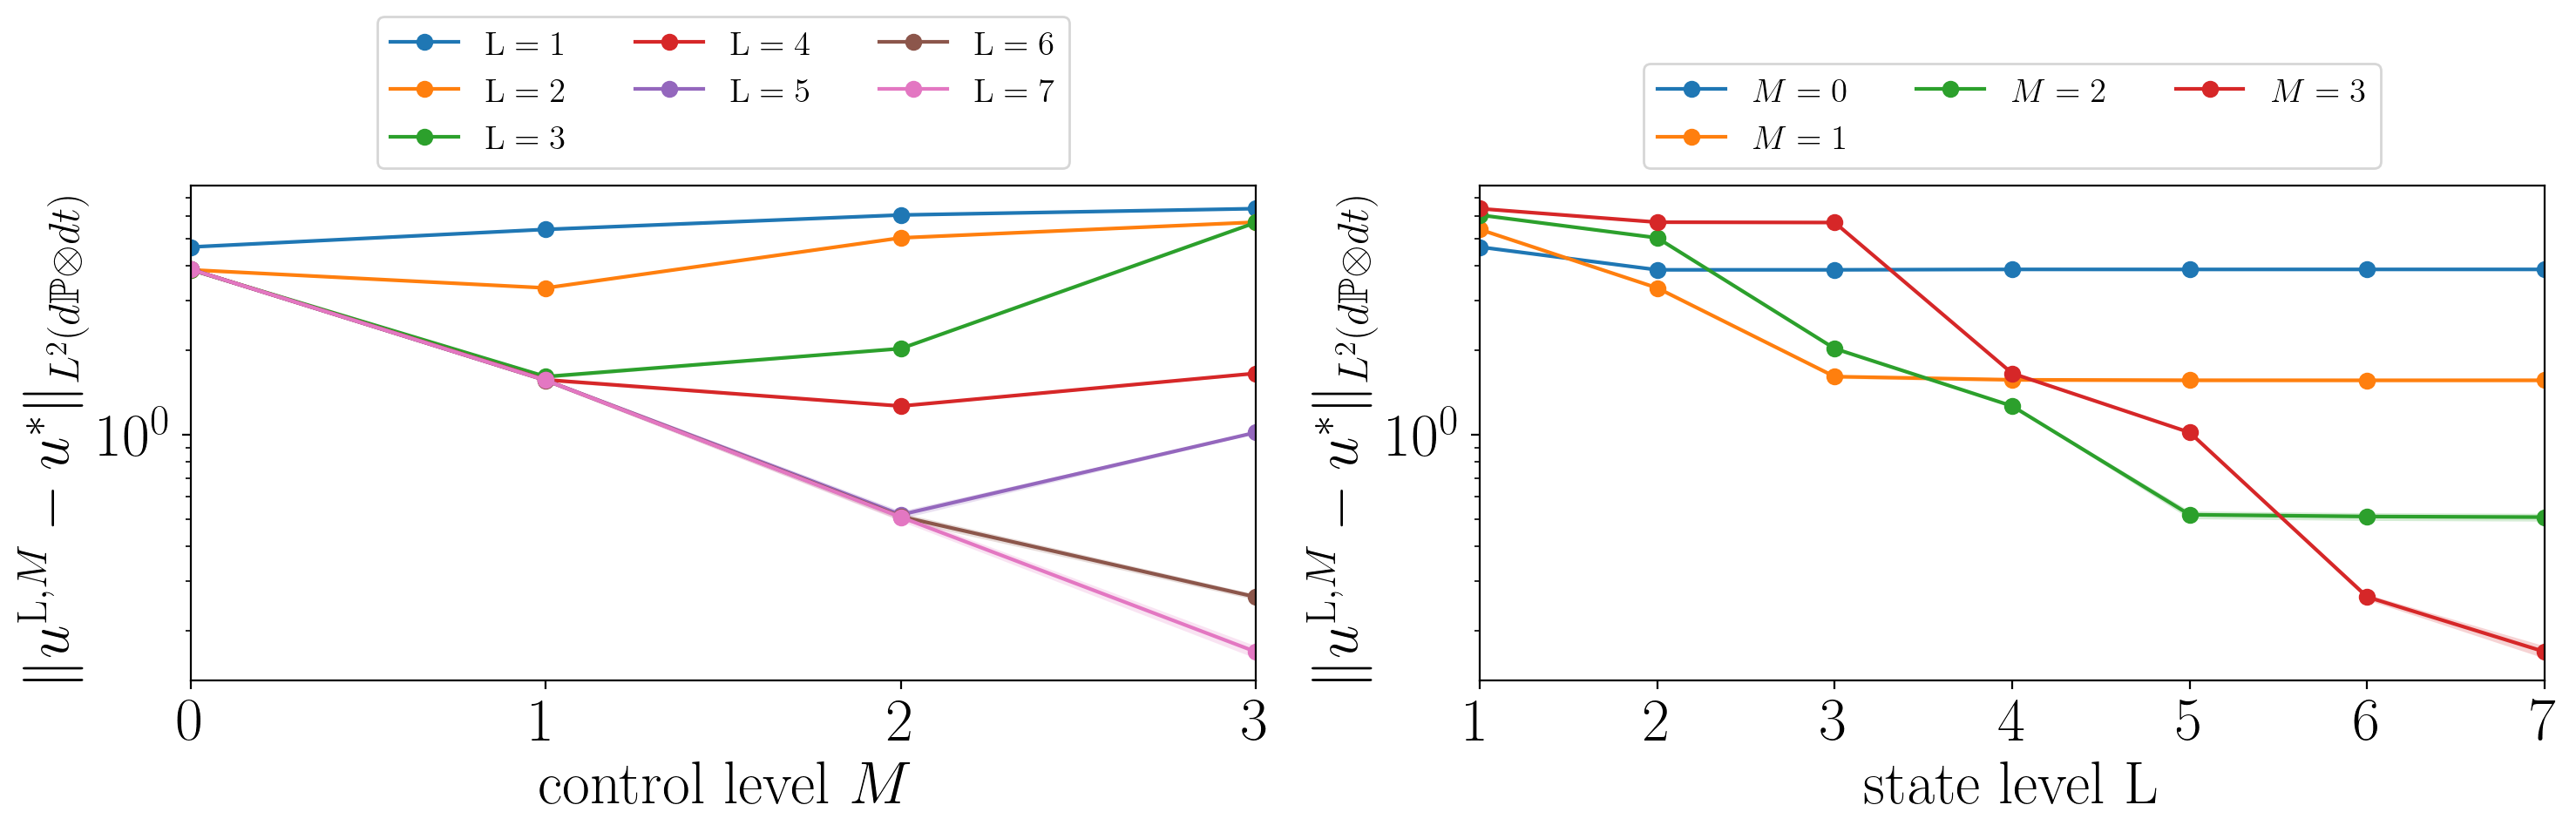

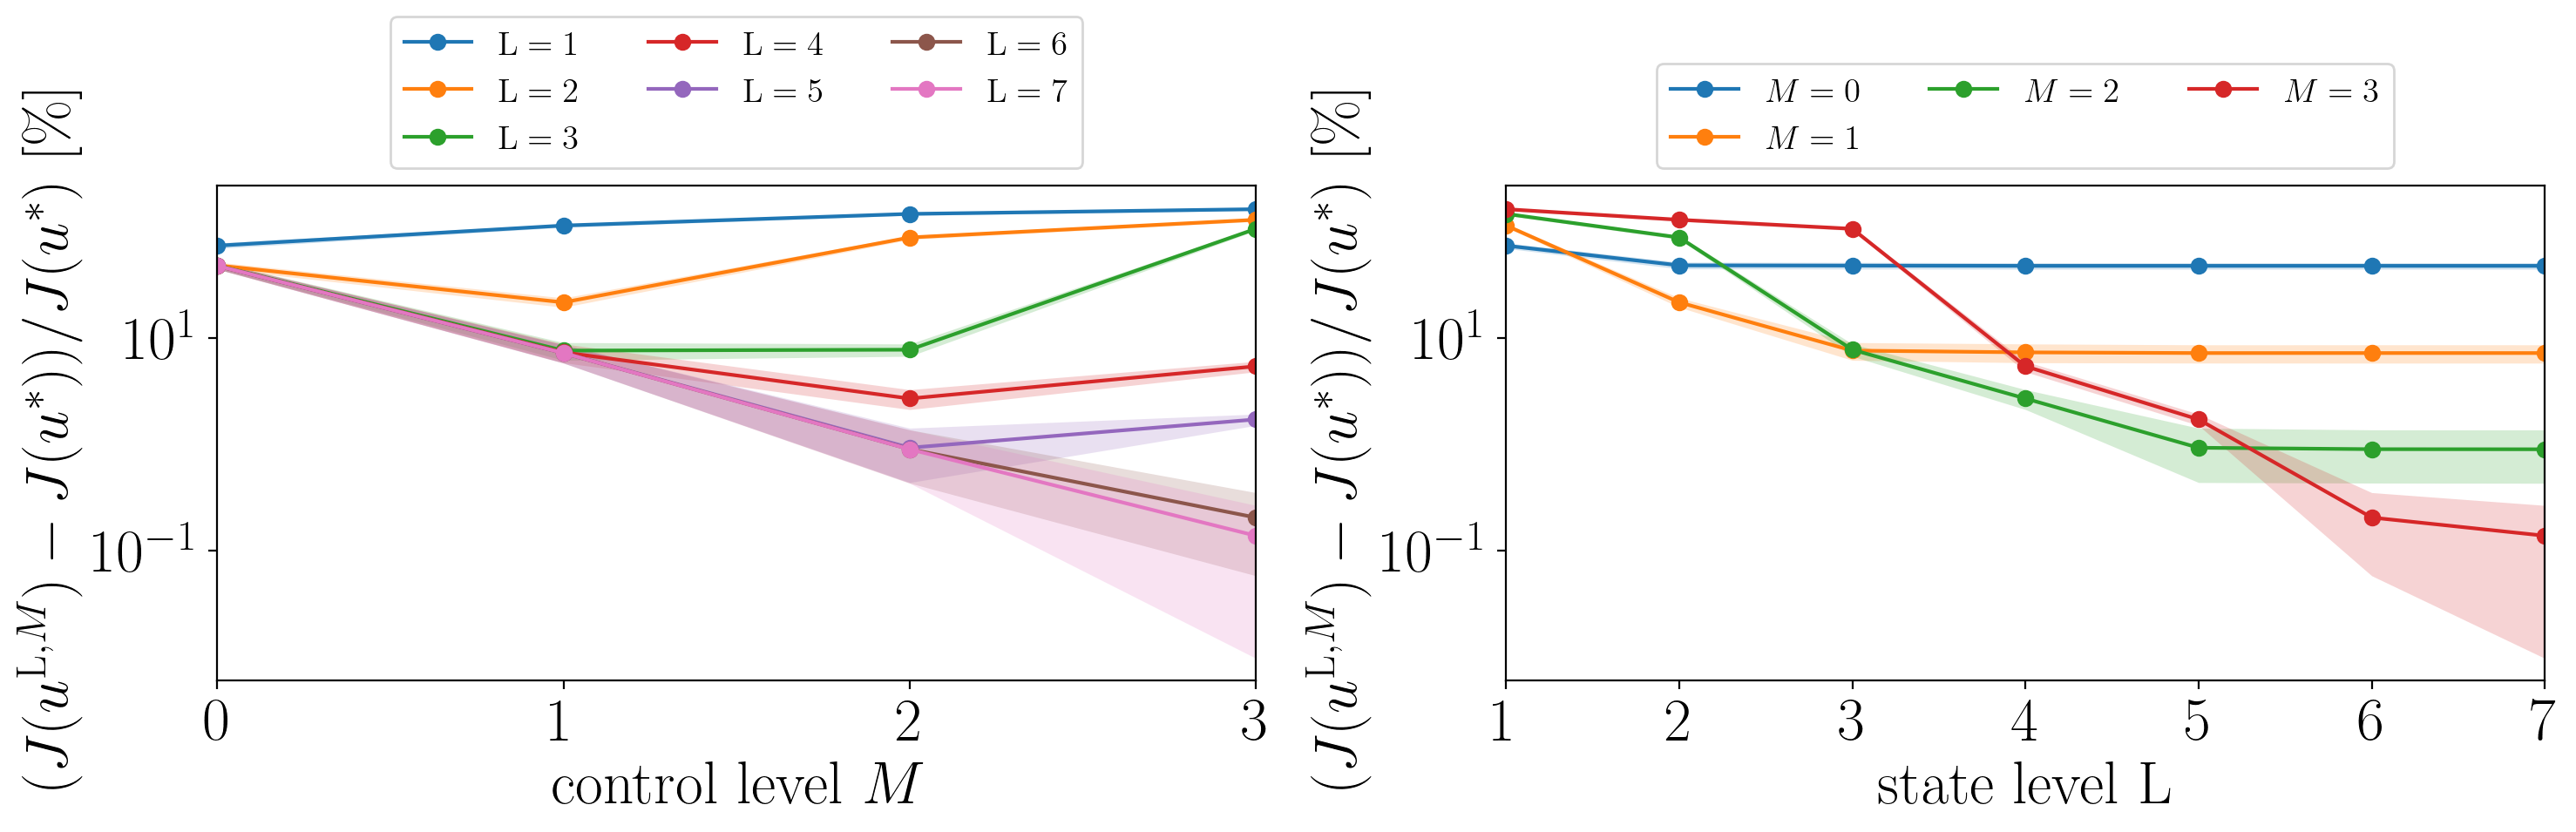

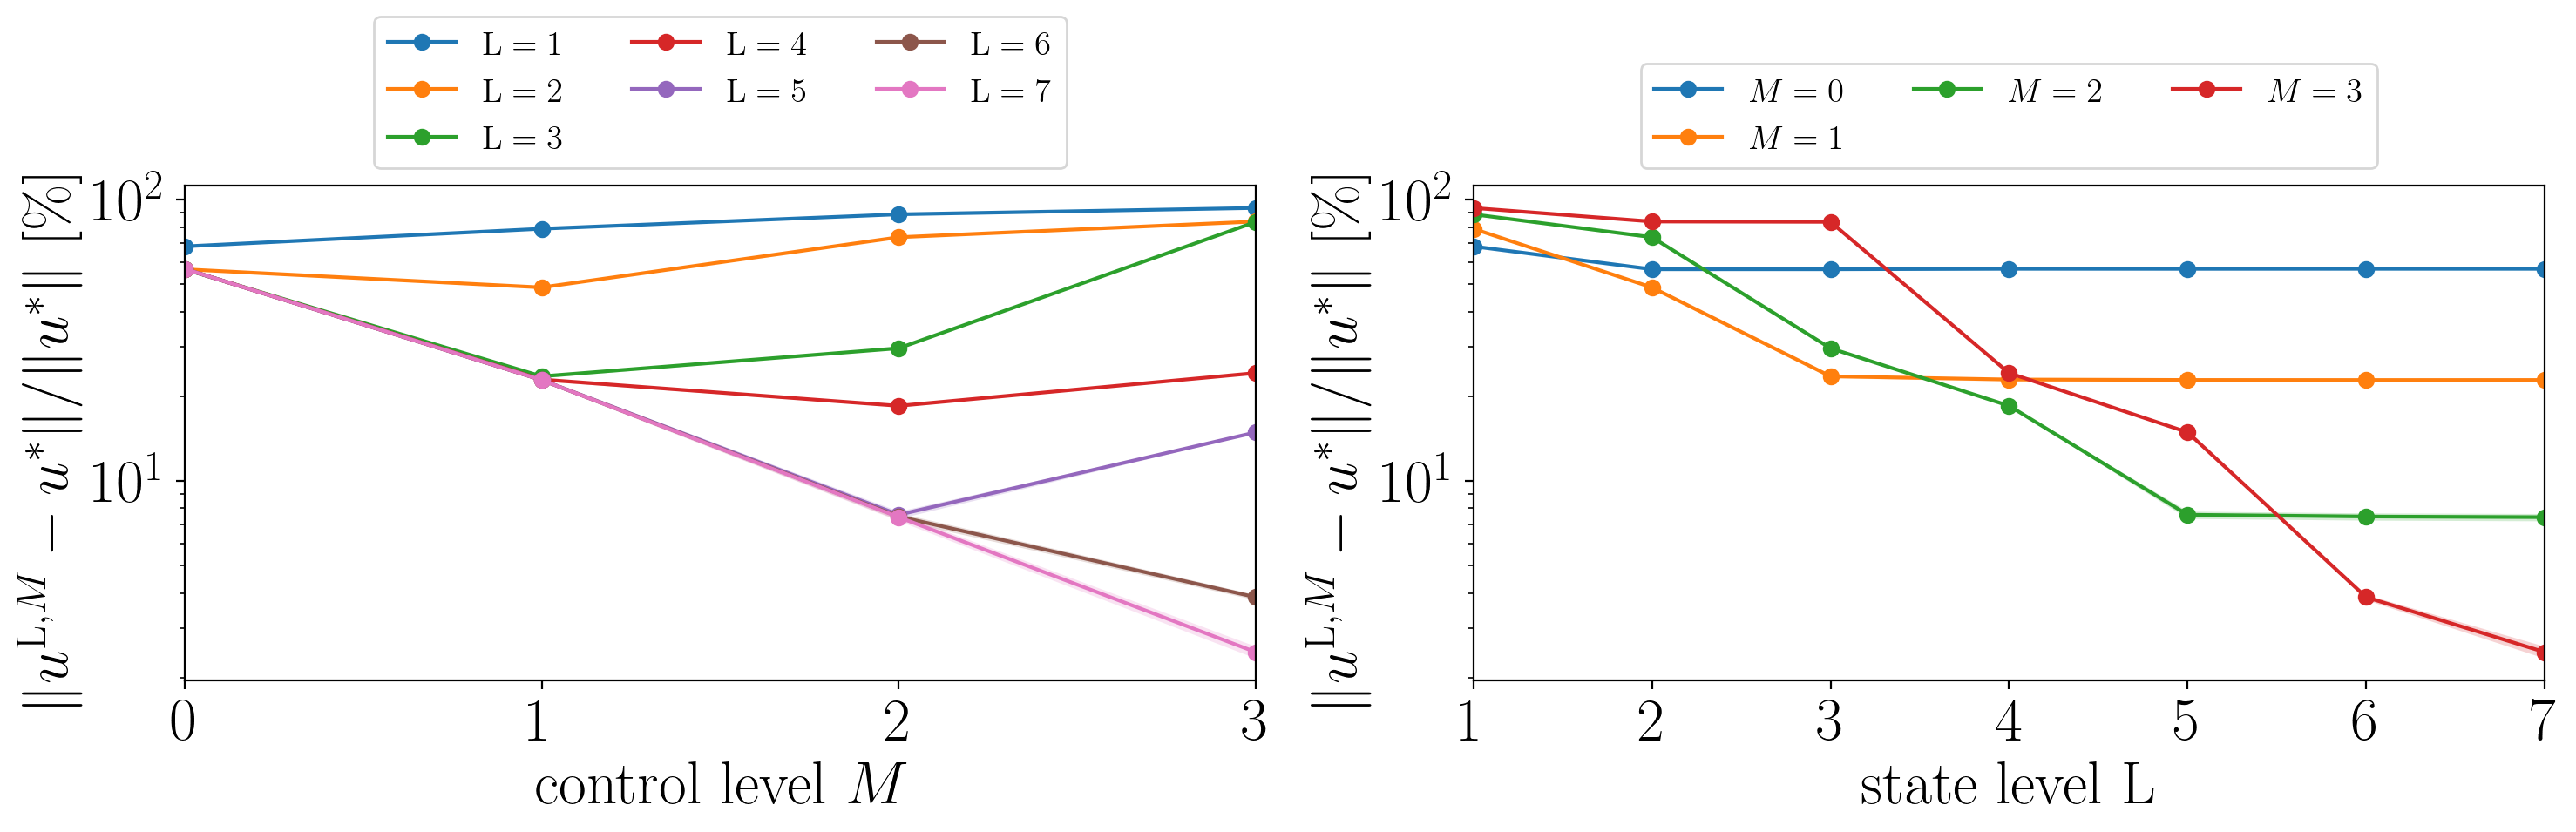

In [5]:
plot_case(mc2, Ls2, Ms2, c_ref2, r"$J(u^*)\ \mathrm{(optimal\ value)}$", "brownian_2d", r"N=D=K=2")

### Sample paths: Brownian, $N=D=K=2$

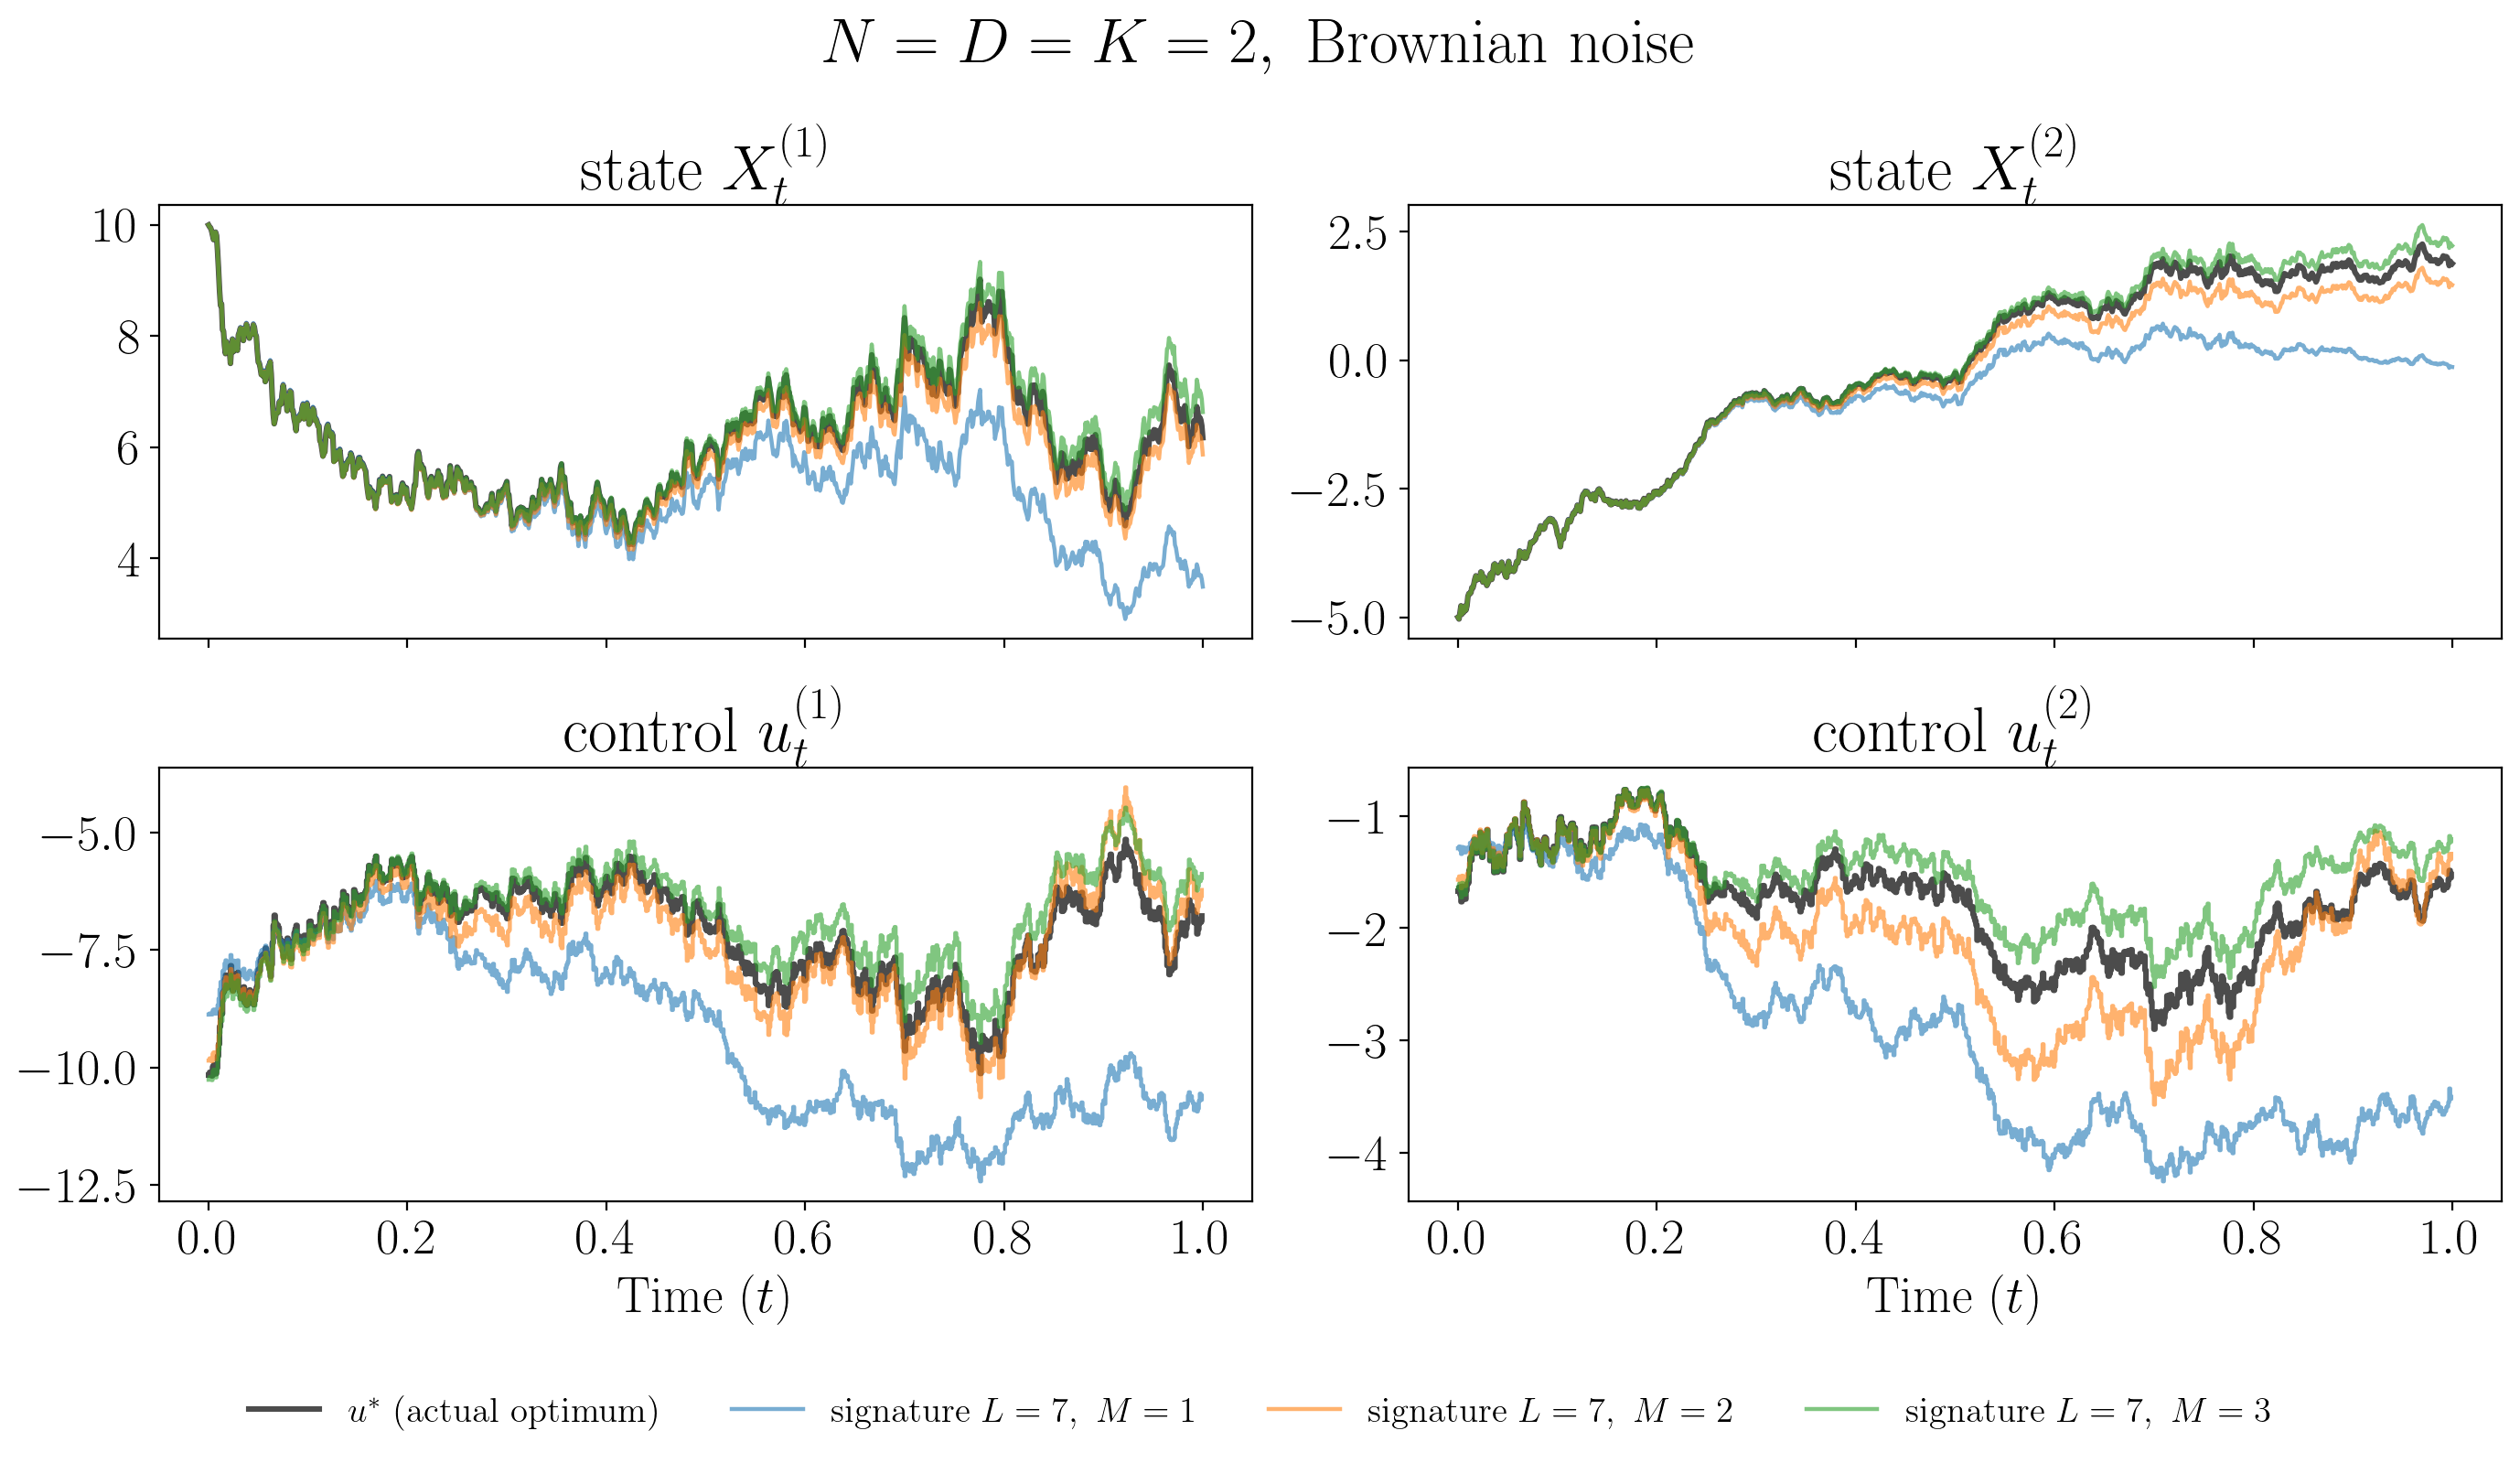

In [6]:
steps_p = 1000; dt_p = mm.T / steps_p
dW_p = np.random.default_rng(SEED + 7).normal(scale=np.sqrt(dt_p), size=(3, steps_p, mm.D))
ctrls = {r"$u^*\ \mathrm{(actual\ optimum)}$": (riccati_feedback(mm, steps_p), 0)}
for (L, M) in [(max(Ls2), M) for M in (1, 2, 3)]:
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(sols2[(L, M)]['theta'], mm, M), M)
_ = compare_paths(mm, dW_p, dt_p, ctrls, simulate, title=r"$N=D=K=2,\ \mathrm{Brownian\ noise}$",
                  fname="brownian_2d_sample_paths")

## Multi-dimensional example: $N=D=K=2$, fBM $H=0.30$, $\sigma_2=0$ (with benchmark)

In [7]:
# ---------------- user settings ----------------
Mmax = 3                     # highest control level M
Lmax = 7                     # highest state truncation level L
nF = 400                     # time steps on [0, T] for the training and test paths
LM_grid = None               # None = all pairs with 1 <= M <= Mmax and M < L <= Lmax,
                             # or your own list, e.g. [(2, 1), (4, 2), (6, 3)]

if LM_grid is None:
    LM_grid = [(L, M) for M in range(1, Mmax + 1) for L in range(M + 1, Lmax + 1)]
assert all(1 <= M <= Mmax and 1 <= L <= Lmax for L, M in LM_grid), "every (L, M) must satisfy L <= Lmax and M <= Mmax"

# ---------------- model, benchmark, noise (cheap: recomputed in both modes) ----------------
mm0 = LQModel(T=mm.T, X0=mm.X0, b0=mm.b0, b1=mm.b1, b2=mm.b2, sigma0=mm.sigma0, sigma2=np.zeros_like(mm.sigma2),
              A=mm.A, B=mm.B, C=mm.C, Dlin=mm.Dlin, E=mm.E, G=mm.G)
H2 = 0.30; chol2 = fbm_cholesky(H2, nF, mm0.T); dt2 = mm0.T / nF
bench2 = dpd_benchmark(mm0, H2, nF, chol=chol2)
n_train2 = 10000
dB_test2, xi_test2 = fbm_increments(H2, 4000, nF, 2, mm0.T, np.random.default_rng(SEED + 21), chol=chol2, return_xi=True)
V2 = bench2['V_of'](xi_test2)

if MODE == "compute":
    # ---------------- functionals ----------------
    t0 = time.perf_counter()
    dB_train2 = fbm_increments(H2, n_train2, nF, 2, mm0.T, np.random.default_rng(SEED + 20), chol=chol2)
    F2_full = EmpiricalCostFunctionals(mm0, Lmax, Mmax, dB_train2, dt2, record_every=4)
    t_F2 = time.perf_counter() - t0
    del dB_train2; gc.collect()

    # ---------------- fits ----------------
    ctrls2 = {"u* (DPD)": (bench2['control'](V2), 0)}
    train_obj = {}
    for (L, M) in LM_grid:
        r = solve_signature_lq(mm0, L, M, F=F2_full.restrict(L, M))
        k = f"closed form L={L}, M={M}"
        ctrls2[k] = (signature_control(r['theta'], mm0, M), M); train_obj[k] = r['value']

    # ---------------- out-of-sample evaluation ----------------
    ev2 = evaluate_controls(mm0, ctrls2, dB_test2, dt2, reference="u* (DPD)")
    cache_save("fbm_additive", t_F2=t_F2, train_obj=train_obj, ev2=ev2, Lmax=Lmax, Mmax=Mmax, nF=nF, LM_grid=LM_grid)
else:
    _c = cache_load("fbm_additive")
    assert (_c['Lmax'], _c['Mmax'], _c['nF'], _c['LM_grid']) == (Lmax, Mmax, nF, LM_grid), \
        "the user settings above differ from those of the cached run"
    globals().update(_c)
print(f"empirical functionals (L={Lmax}, M={Mmax}, {n_train2} paths): {t_F2:.1f}s")
print(f"\nMC test cost of u* (DPD): {fmt_mc(ev2['u* (DPD)']['cost'], 5)}   [mean ± 95% CI]")
print(f"{'control':>26} | {'train J^L':>9} | {'excess over u* (paired): mean ± 95% CI':>45} | L2 to u* [± 95% CI]")
for k, v in ev2.items():
    if k == "u* (DPD)": continue
    tr = f"{train_obj[k]:9.5f}" if k in train_obj else " " * 9
    print(f"{k:>26} | {tr} | {fmt_mc(v['diff'], 5):>45} | {fmt_l2(v['d2'], 4)}")

empirical functionals (L=7, M=3, 10000 paths): 267.4s

MC test cost of u* (DPD): 30.50439 ± 0.19014   [mean ± 95% CI]
                   control | train J^L |        excess over u* (paired): mean ± 95% CI | L2 to u* [± 95% CI]
      closed form L=2, M=1 |  33.47561 |                             5.49742 ± 0.00910 | 2.9022 ± 0.0012
      closed form L=3, M=1 |  27.99756 |                             0.38349 ± 0.00278 | 0.7013 ± 0.0011
      closed form L=4, M=1 |  31.06561 |                             0.05408 ± 0.00145 | 0.2769 ± 0.0007
      closed form L=5, M=1 |  30.51098 |                             0.03727 ± 0.00137 | 0.2226 ± 0.0008
      closed form L=6, M=1 |  30.60596 |                             0.03678 ± 0.00138 | 0.2224 ± 0.0007
      closed form L=7, M=1 |  30.59245 |                             0.03677 ± 0.00137 | 0.2222 ± 0.0008
      closed form L=3, M=2 |  19.12634 |                             6.10701 ± 0.03408 | 2.7237 ± 0.0046
      closed form L=4, M=2 |  30.03284

MC test cost of u* (DPD): 30.50439 ± 0.19014   [mean ± 95% CI]

excess cost J(u^{L,M}) − J(u*)  [paired MC: mean ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:      3.51122 ± 0.05372      17.55597 ± 0.18267      25.82735 ± 0.25347      29.59408 ± 0.27875
L=2:      1.23978 ± 0.02965       5.49742 ± 0.00910      32.56752 ± 0.29061      34.77138 ± 0.29538
L=3:      1.18049 ± 0.03127       0.38349 ± 0.00278       6.10701 ± 0.03408      34.38198 ± 0.30499
L=4:      1.17118 ± 0.03031       0.05408 ± 0.00145       1.08480 ± 0.00935       8.76132 ± 0.05796
L=5:      1.17073 ± 0.03047       0.03727 ± 0.00137       0.04124 ± 0.00114       3.27349 ± 0.02954
L=6:      1.17073 ± 0.03045       0.03678 ± 0.00138       0.01084 ± 0.00093       0.11930 ± 0.00195
L=7:      1.17073 ± 0.03045       0.03677 ± 0.00137       0.00960 ± 0.00089       0.00819 ± 0.00077

relative excess cost (J(u^{L,M}) − J(u*)) / J(u*)  [%, ± 95% CI]     rows: L, cols: M = [0, 1, 2, 3]
L=1:       11.5106 ± 0.1159        57.5

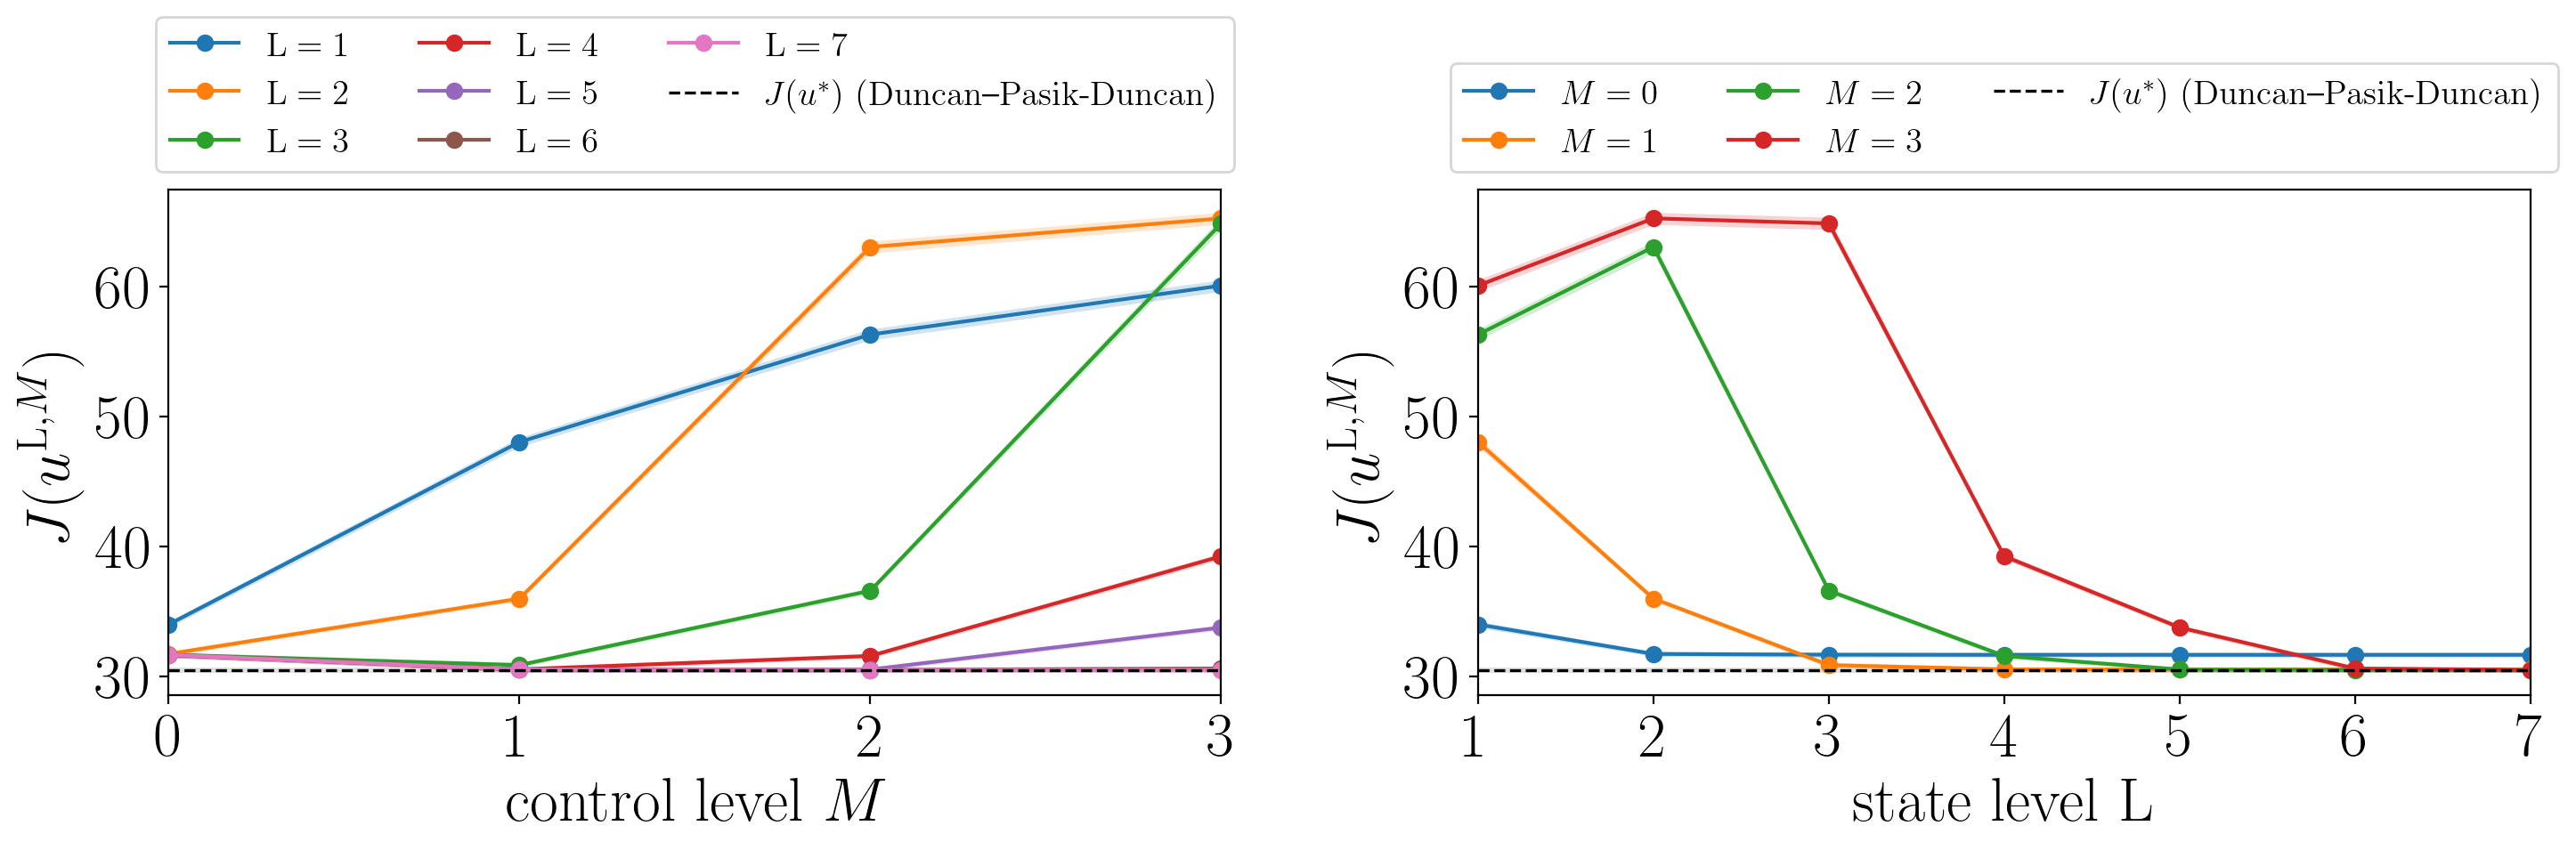

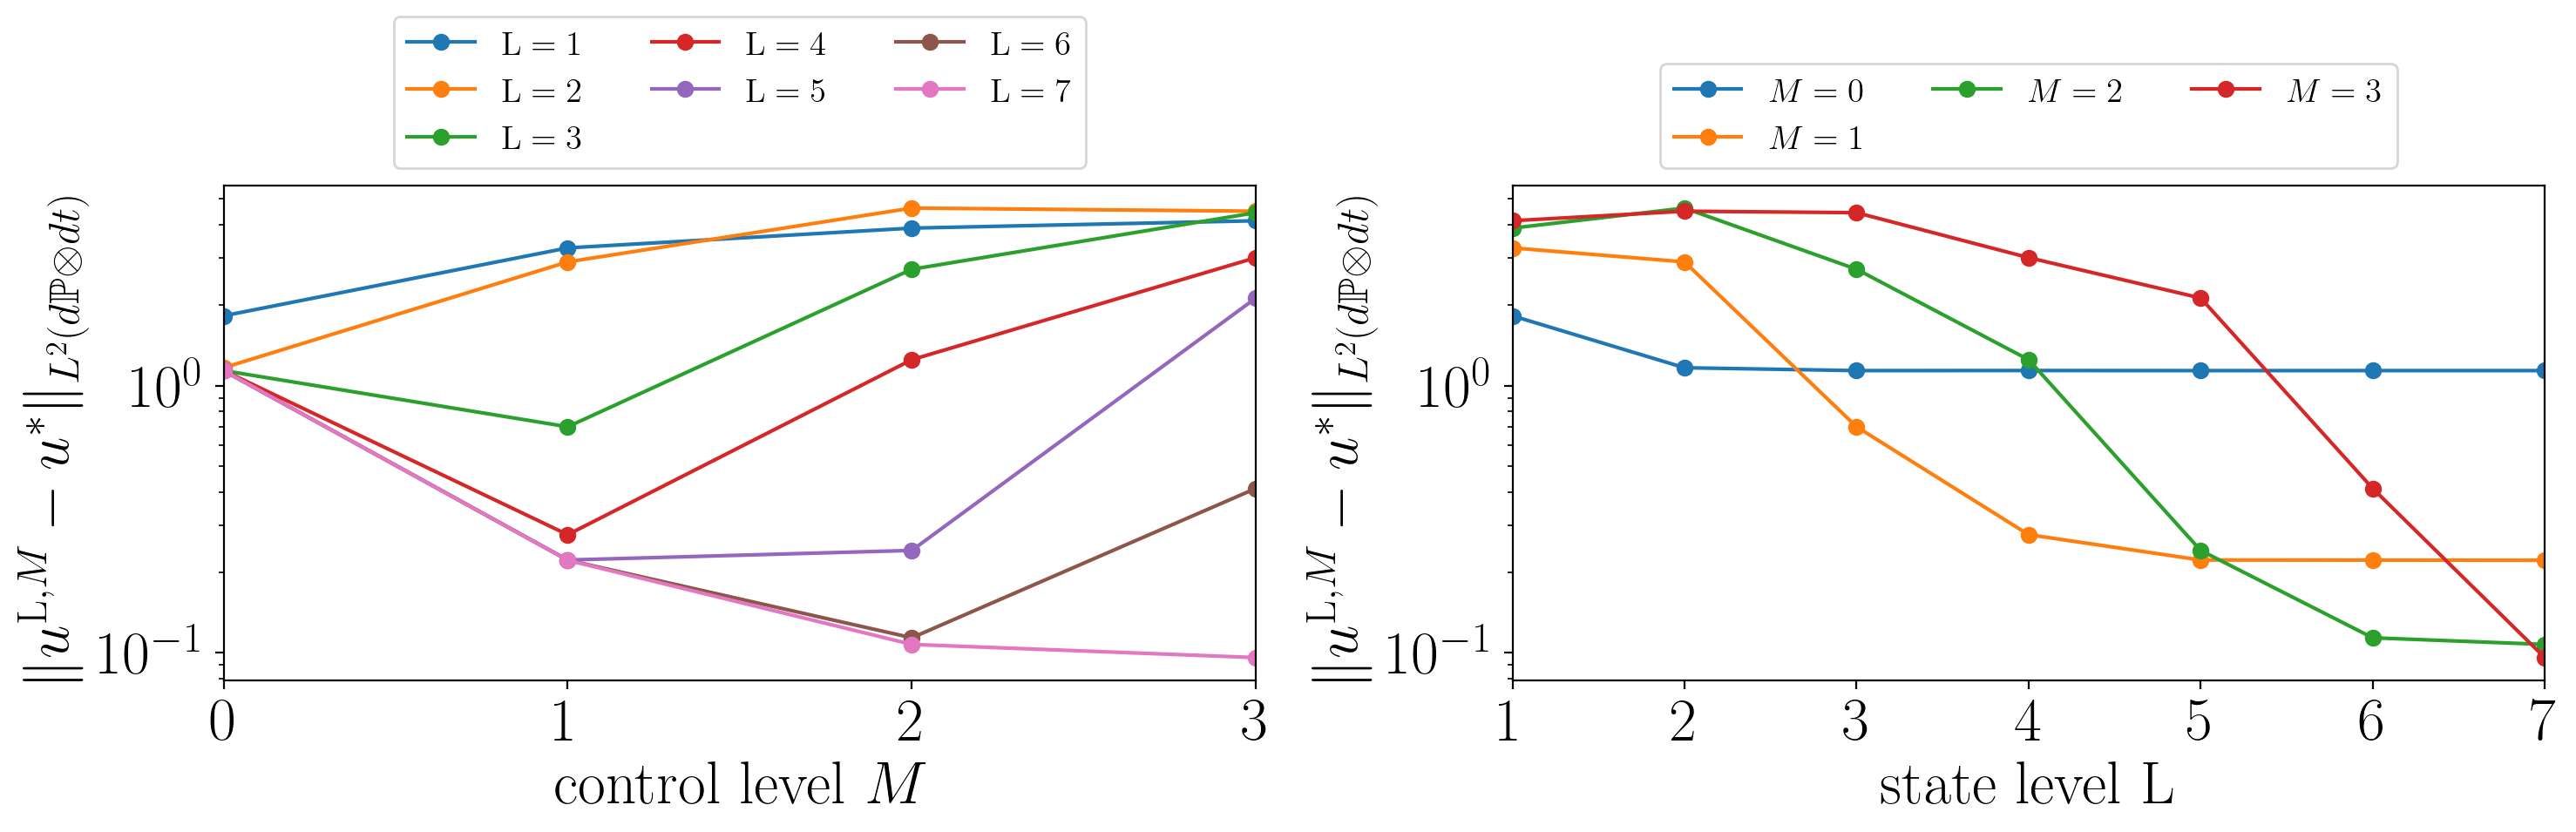

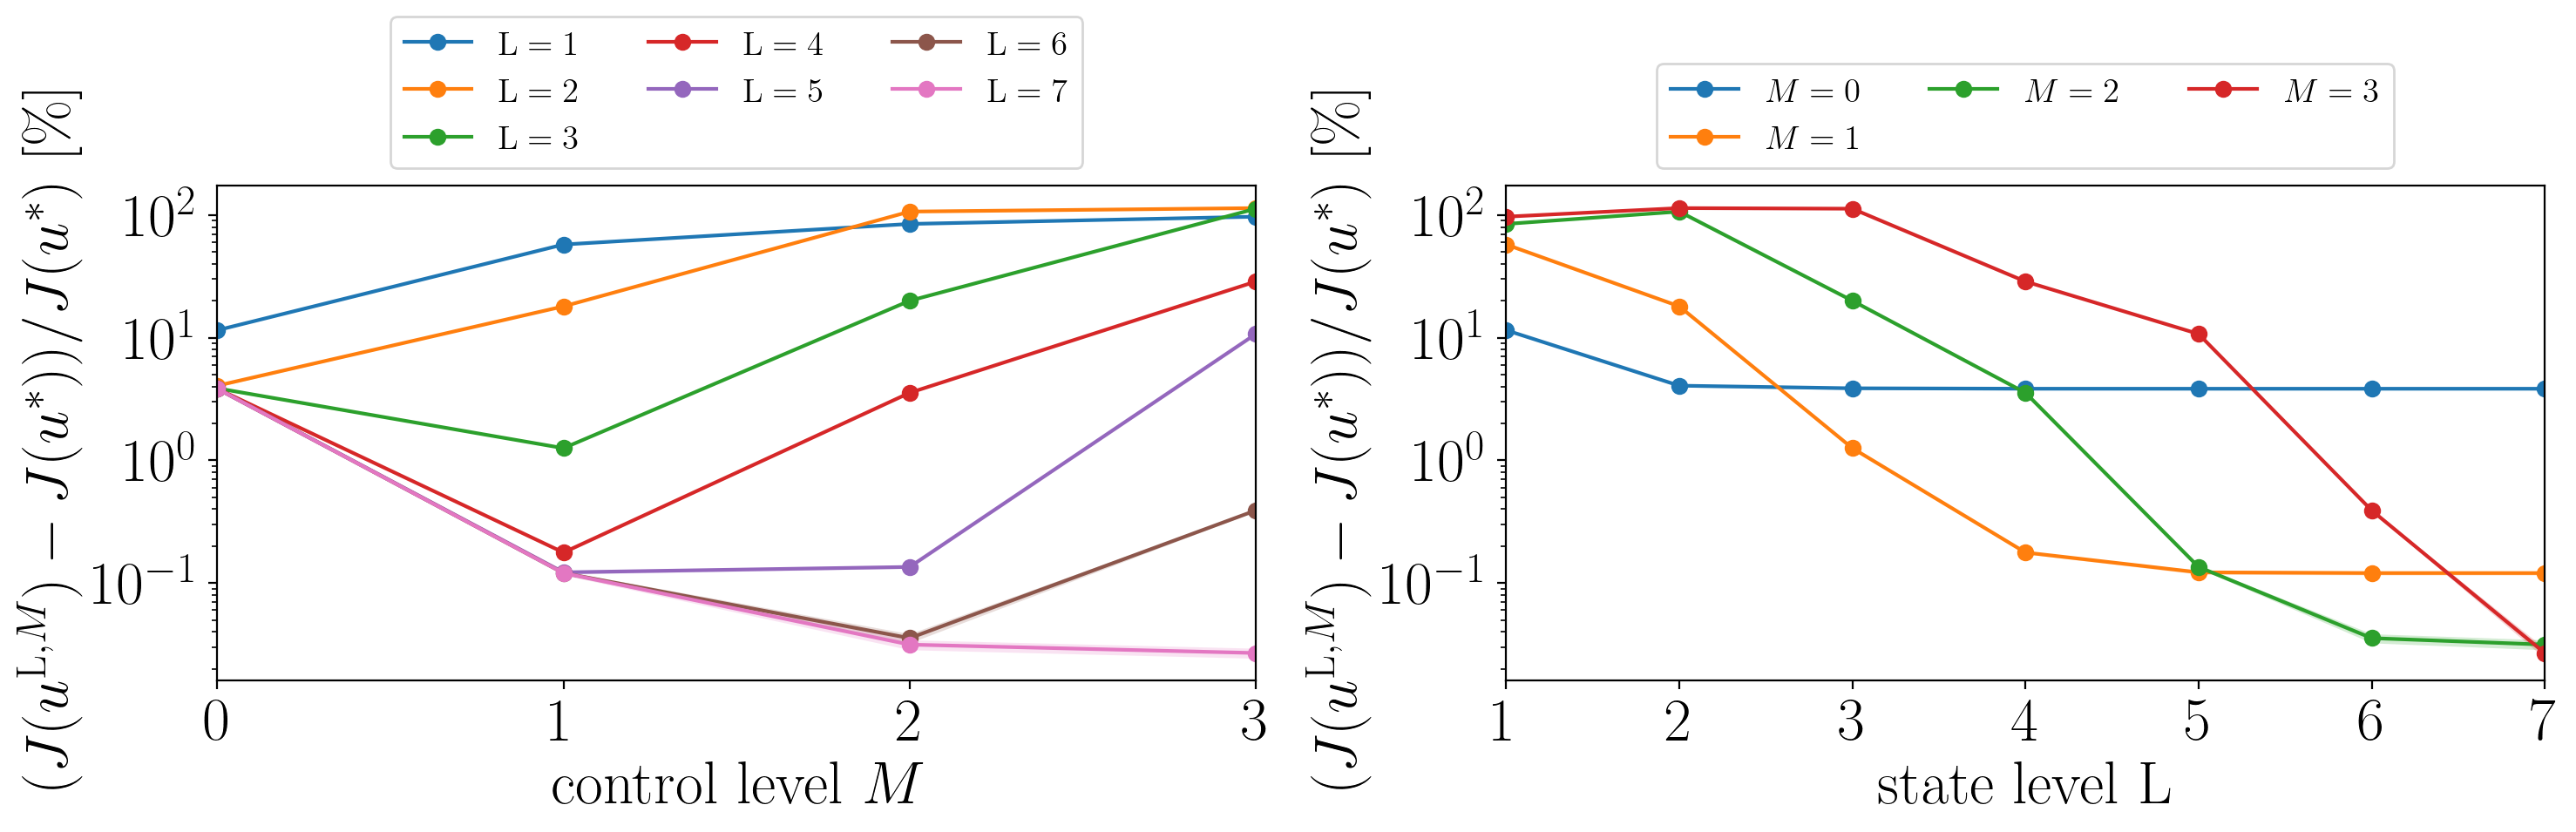

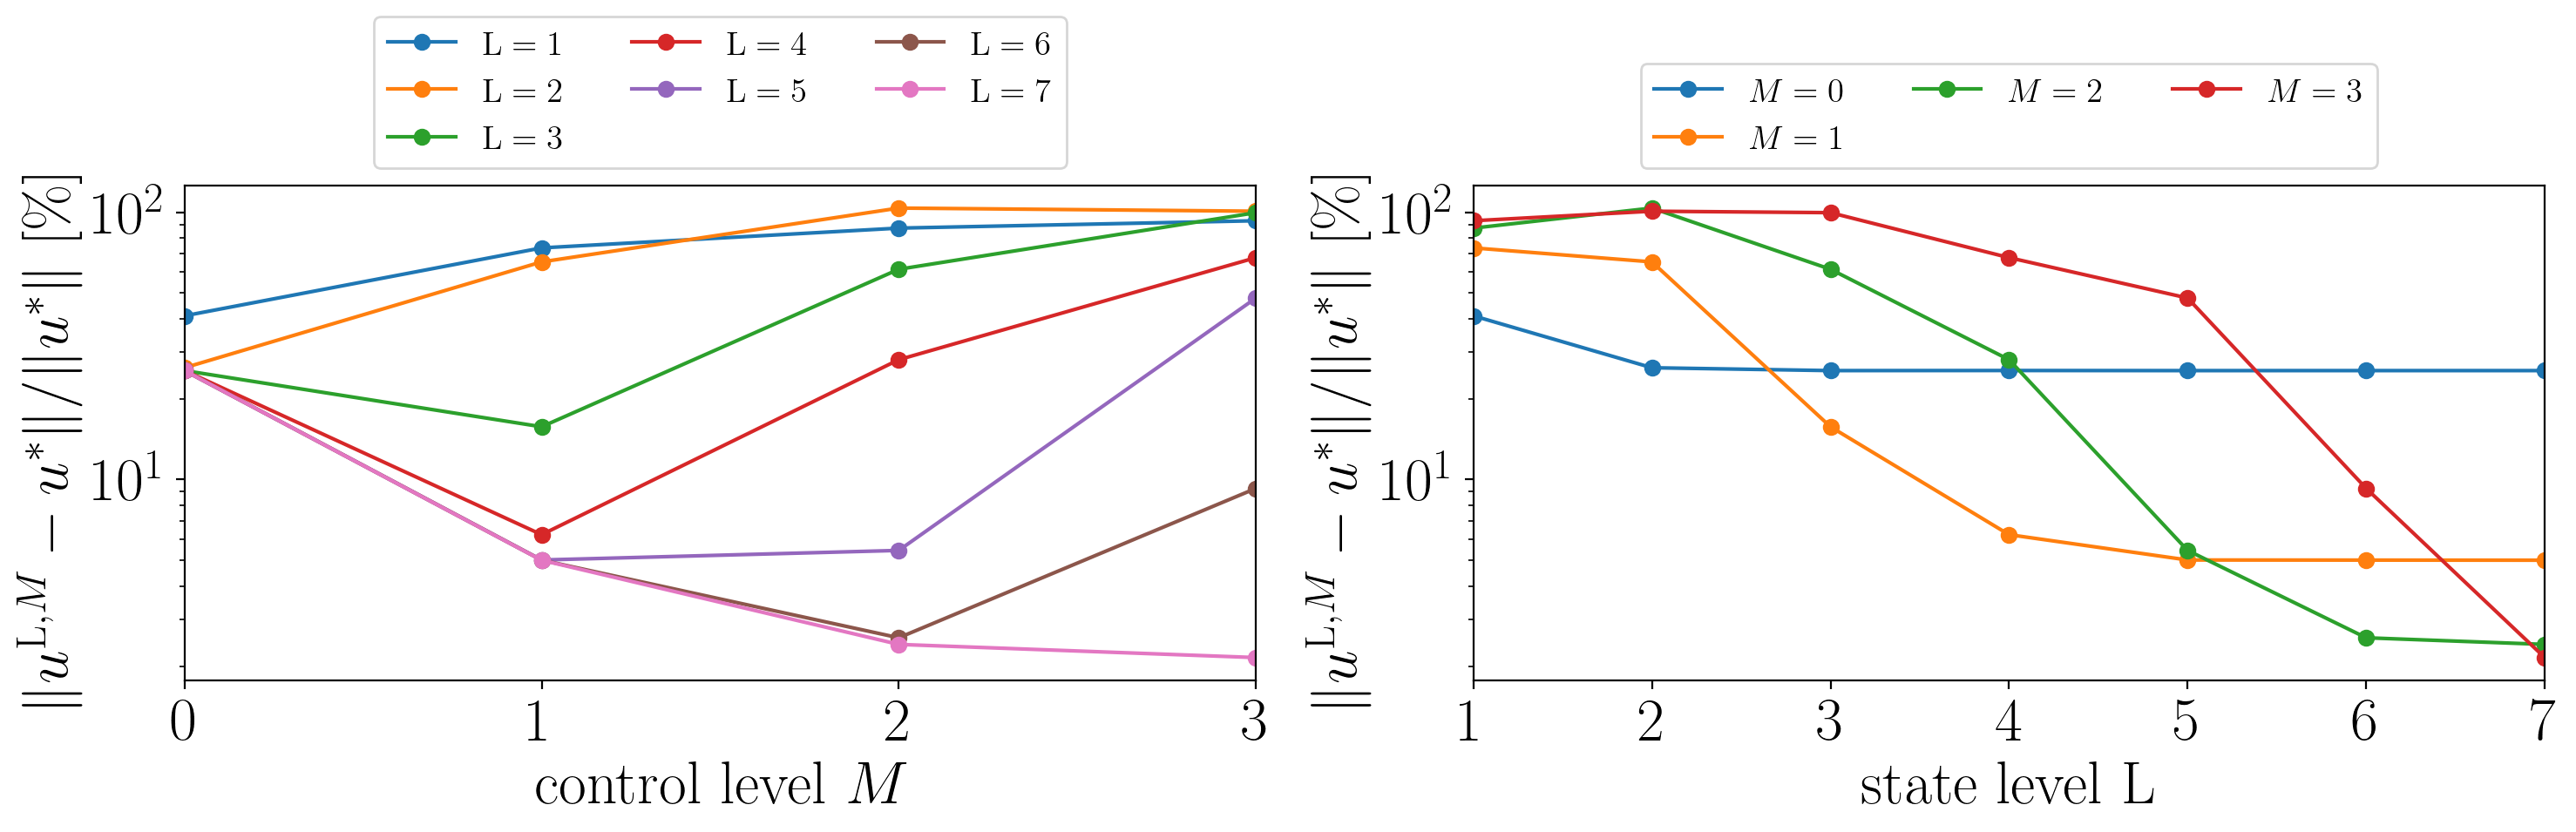

In [8]:
Ls_g2 = list(range(1, Lmax + 1))          # L = 1, ..., Lmax
Ms_g2 = list(range(0, Mmax + 1))          # M = 0 (deterministic polynomial control), 1, ..., Mmax
if MODE == "compute":
    th_g2 = {(L, M): solve_signature_lq(mm0, L, M, F=F2_full.restrict(L, M))['theta'] for L in Ls_g2 for M in Ms_g2}
    cost_g2, c_ref_g2, d2_g2, q2_g2 = simulate_many(mm0, dB_test2, dt2, [(th_g2[k], k[1]) for k in th_g2], bench2['control'](V2))
    cache_save("fbm_additive_grid", th_g2=th_g2, cost_g2=cost_g2, c_ref_g2=c_ref_g2, d2_g2=d2_g2, q2_g2=q2_g2)
else:
    globals().update(cache_load("fbm_additive_grid"))
mc_g2 = mc_grid(list(th_g2), cost_g2, c_ref_g2, d2_g2, q2_g2)
print(f"MC test cost of u* (DPD): {fmt_mc(c_ref_g2, 5)}   [mean ± 95% CI]")
print_grid(mc_g2, Ls_g2, Ms_g2, 5)
H_tag = f"{H2:.2f}".replace(".", "")      # 0.30 -> "030"
plot_case(mc_g2, Ls_g2, Ms_g2, c_ref_g2, tex(r"$J(u^*)\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$"), f"fbm_H{H_tag}_2d",
          rf"\mathrm{{fBM}},\ H={H2:g},\ N=D=K=2")

### Sample paths: fBM, $H=0.30$, $N=D=K=2$

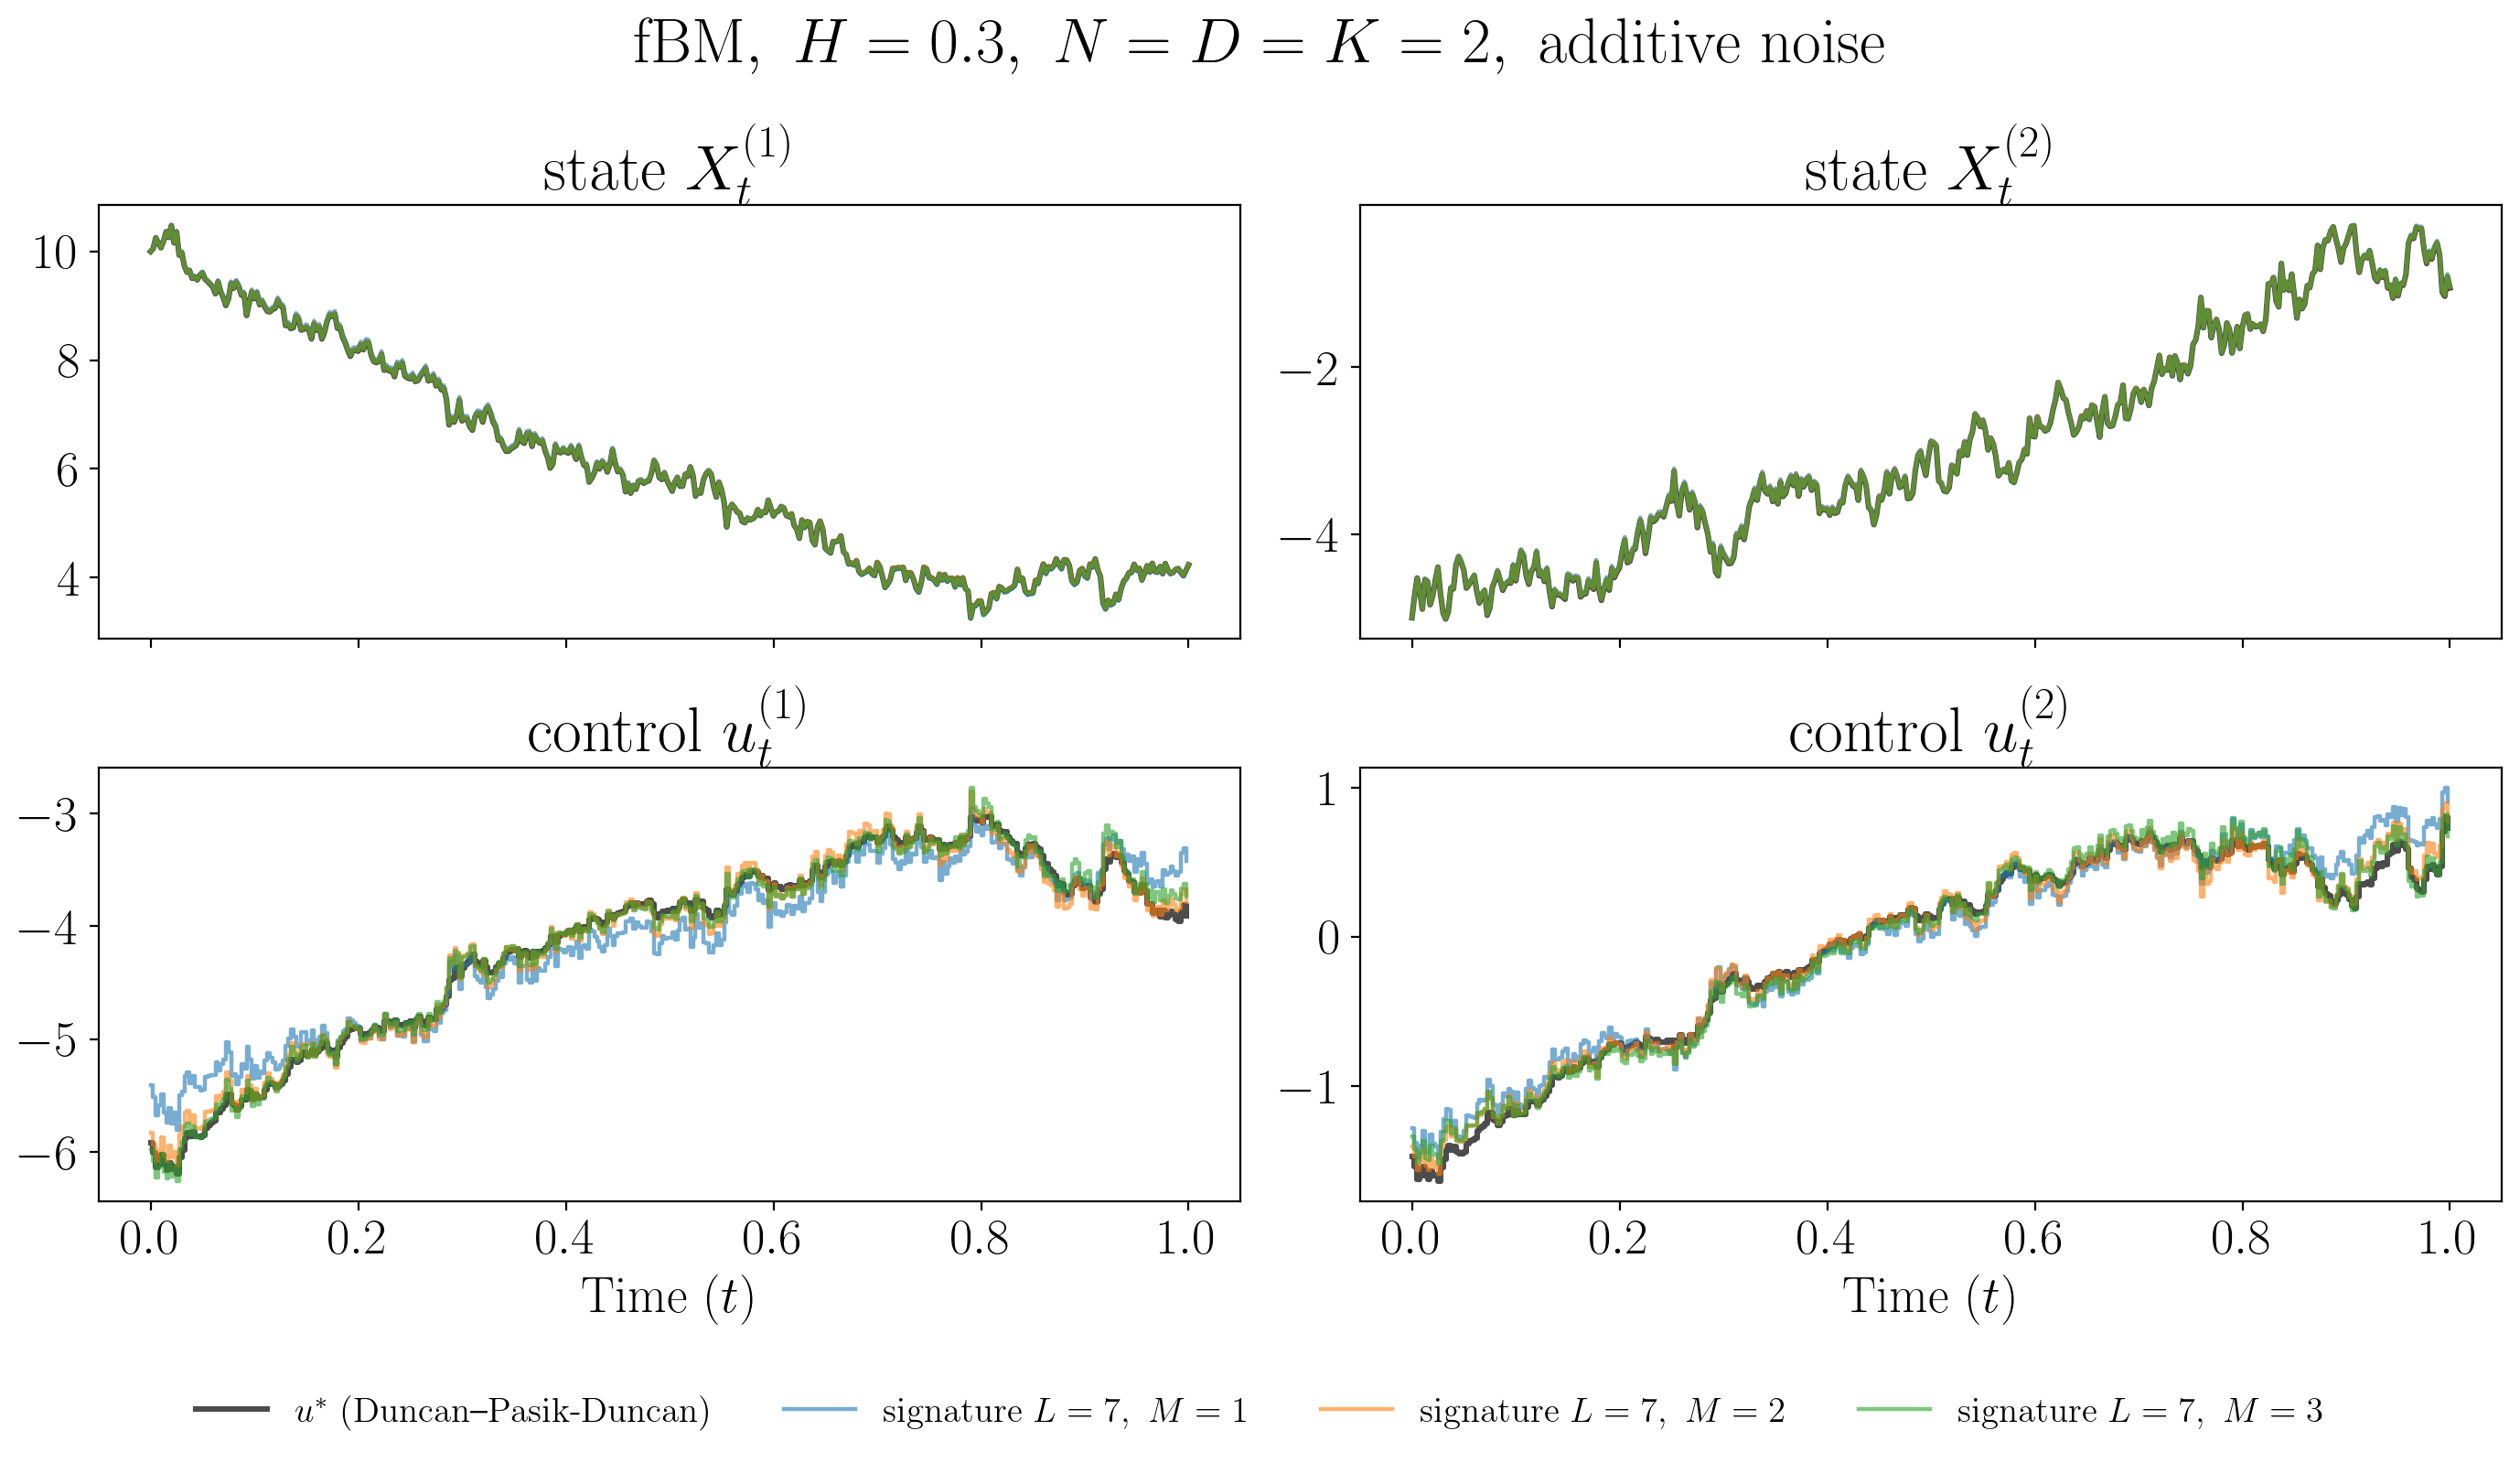

In [9]:
LM_paths = [(Lmax, M) for M in range(1, Mmax + 1)]   # or your own list, e.g. [(3, 1), (5, 2), (Lmax, Mmax)]
missing = [k for k in LM_paths if k not in th_g2]
assert not missing, f"not in the fitted grid th_g2: {missing}"

dBp, xip = dB_test2[:3], xi_test2[:3]                            # first test paths of 7.1
Vp = bench2['V_of'](xip)
ctrls = {tex(r"$u^*\ \mathrm{(Duncan\text{--}Pasik\text{-}Duncan)}$"): (bench2['control'](Vp), 0)}
for (L, M) in LM_paths:
    ctrls[rf"$\mathrm{{signature}}\ L={L},\ M={M}$"] = (signature_control(th_g2[(L, M)], mm0, M), M)
H_tag = f"{H2:.2f}".replace(".", "")
_ = compare_paths(mm0, dBp, dt2, ctrls, simulate_driver,
                  title=rf"$\mathrm{{fBM}},\ H={H2:g},\ N=D=K=2,\ \mathrm{{additive\ noise}}$",
                  fname=f"fbm_H{H_tag}_2d_sample_paths")